# Solutions: Chapter 15, Visualization with Matplotlib

Worked solutions to the exercises at the end of Chapter 15 of *Python for Data Science* by Vamsi Krishna Kandala. Try each exercise on your own first. Run the code yourself with the notebook [`ch15_solutions.ipynb`](ch15_solutions.ipynb) or the script `ch15_solutions.py`.

Numbers that depend on random data or library versions may differ slightly on your computer; the conclusions should not.


In [ ]:
# Setup: recreates the context these solutions build on (from the chapter).
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

gap = pd.read_csv("data/gapminder.csv")
penguins = pd.read_csv("data/penguins.csv")
orders = pd.read_parquet("data/shop_orders.parquet")
orders = orders[orders["status"] != "cancelled"]

The solutions use the Gapminder, penguin and coffee-shop data, loaded as in the chapter.

## Exercise 15.1

*Draw a line chart of world population per year from Gapminder, in billions, with a title and axis labels.*

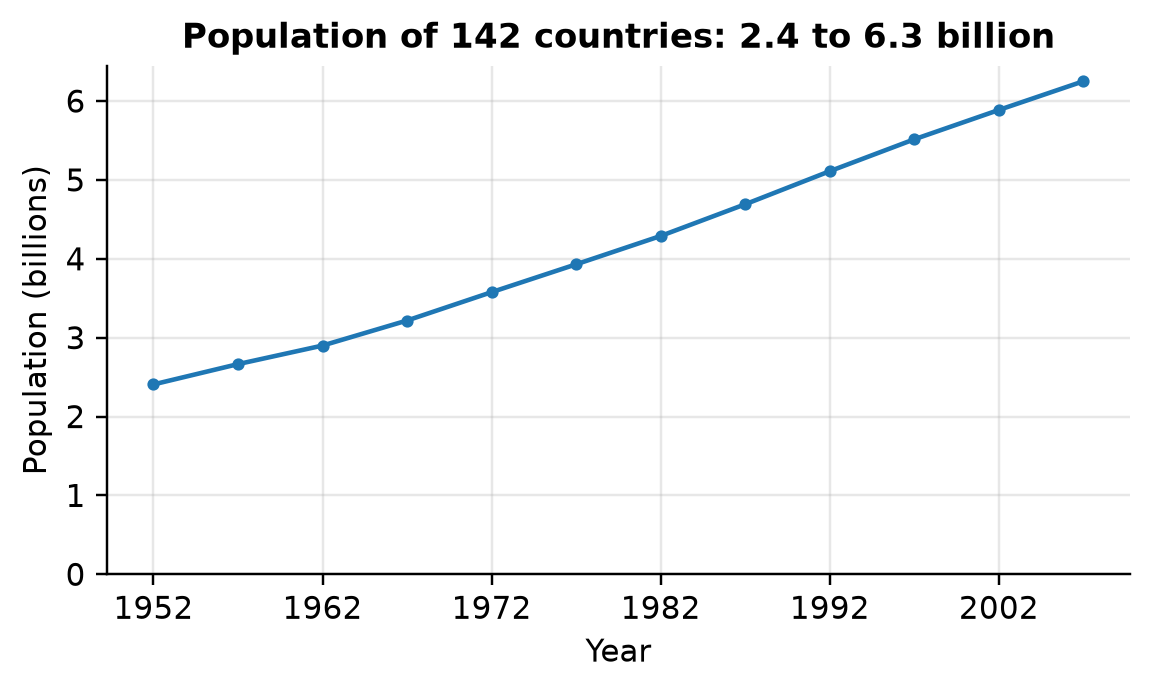

In [ ]:
world = gap.groupby("year")["pop"].sum() / 1e9
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(world.index, world.values, marker="o", markersize=3)
ax.set_xticks(world.index[::2])
ax.set_ylim(0, None)
ax.set_xlabel("Year")
ax.set_ylabel("Population (billions)")
ax.set_title(f"Population of 142 countries: {world.iloc[0]:.1f} to "
             f"{world.iloc[-1]:.1f} billion")
plt.show()

*The total population of Gapminder's 142 countries, 1952 to 2007.*

Summing over countries per year gives the total; dividing by `1e9` gives billions. `set_ylim(0, None)` starts the axis at zero and lets Matplotlib choose the top, so the growth isn't exaggerated. The 142 countries don't cover the whole world, which the title says: their population more than doubled, from about 2.4 to 6.3 billion.

## Exercise 15.2

*Draw a sorted horizontal bar chart of the number of penguins per island, with the counts written at the ends of the bars.*

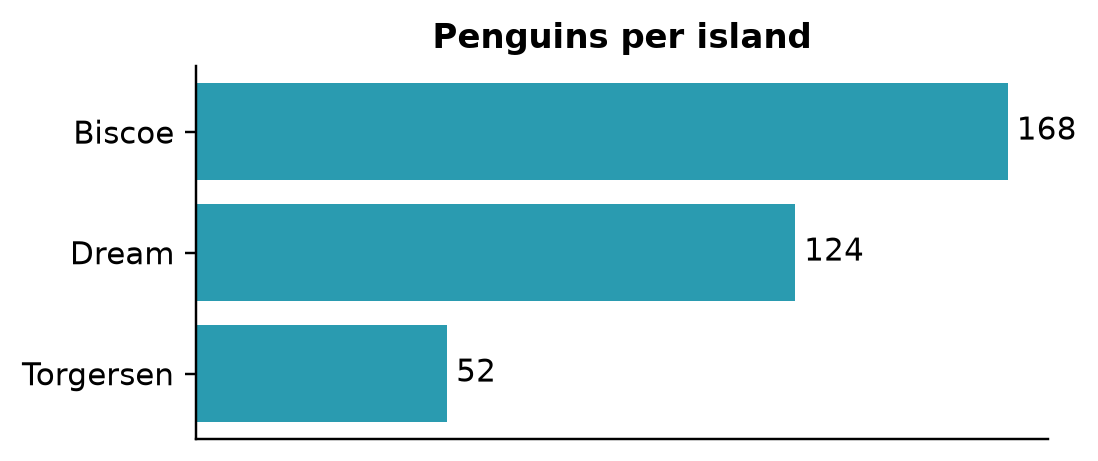

In [ ]:
counts = penguins["island"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(5, 2.2))
bars = ax.barh(counts.index, counts.values, color="#2a9bb0")
ax.bar_label(bars, padding=3)
ax.set_xticks([])
ax.grid(False)
ax.set_title("Penguins per island")
plt.show()

*The number of penguins per island, sorted, with counts at the ends of the bars.*

With every bar labeled, the x axis adds nothing, so `set_xticks([])` and `grid(False)` remove it. Biscoe has the most penguins, Torgersen the fewest.

## Exercise 15.3

*Draw a scatter chart of bill length against bill depth, with a different color and marker for each species and a legend.*

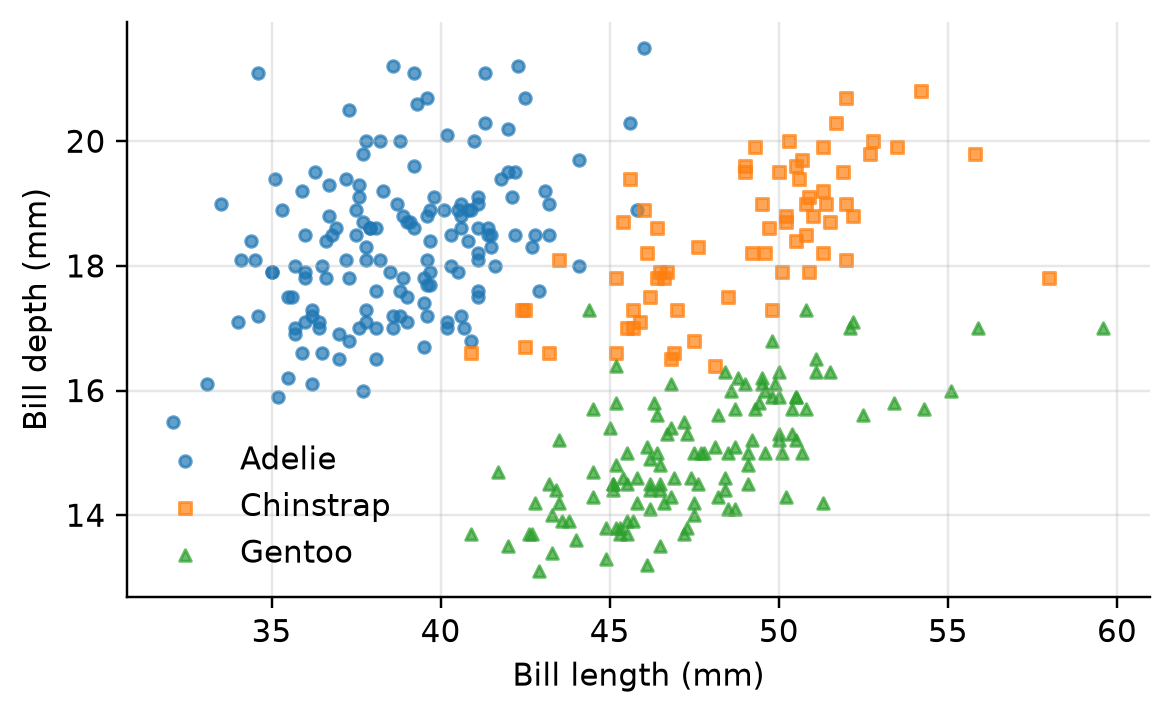

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for (name, group), marker in zip(penguins.groupby("species"), "os^"):
    ax.scatter(group["bill_length_mm"], group["bill_depth_mm"], s=14,
               marker=marker, label=name, alpha=0.7)
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.legend()
plt.show()

*Bill length against bill depth, one color and marker per species.*

Iterating over `groupby("species")` gives each species' name and rows, drawn as separate scatters with their own marker. In one cloud, the points would show a weak downward trend; split by species, each group shows longer bills going with deeper ones, and the species occupy separate regions. Chapter 16 names this Simpson's paradox.

## Exercise 15.4

*Draw small multiples of life expectancy over time, one axes per continent, each showing the median and the range from the minimum to the maximum across countries.*

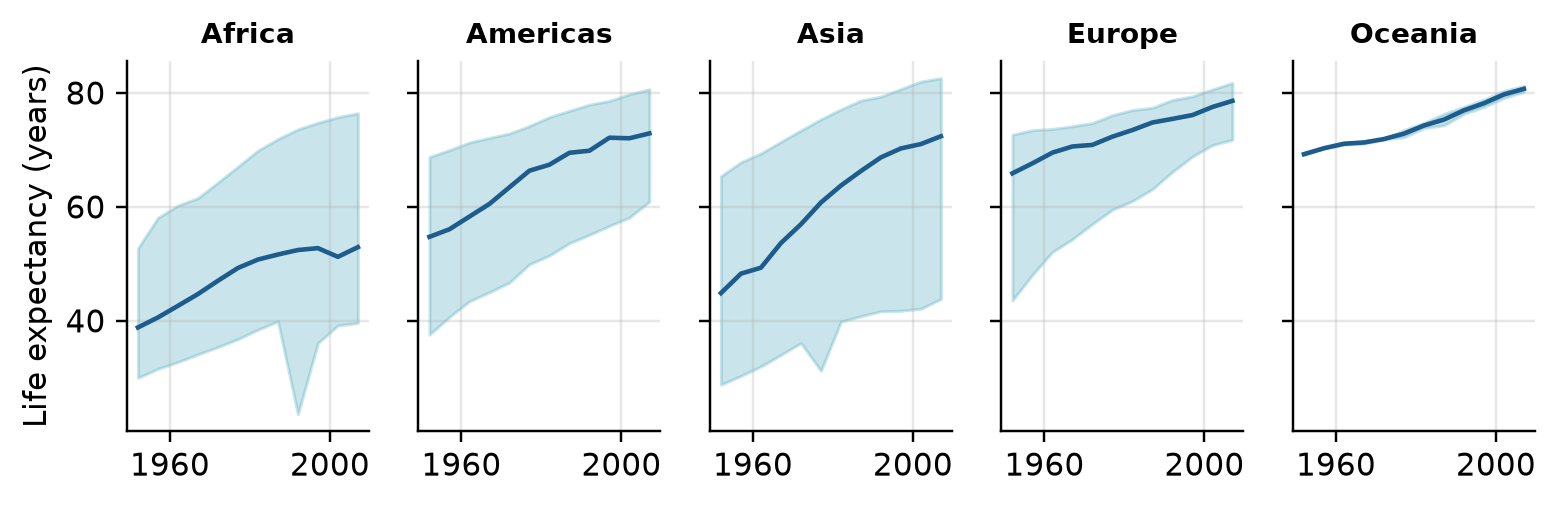

In [ ]:
stats = gap.groupby(["continent", "year"])["lifeExp"].agg(
    ["min", "median", "max"])
continents = stats.index.get_level_values(0).unique()
fig, axes = plt.subplots(1, 5, figsize=(7.2, 2.4), sharey=True)
for ax, name in zip(axes, continents):
    s = stats.loc[name]
    ax.fill_between(s.index, s["min"], s["max"], alpha=0.25,
                    color="#2a9bb0")
    ax.plot(s.index, s["median"], color="#1d5c8c")
    ax.set_title(name, fontsize=9)
    ax.set_xticks([1960, 2000])
axes[0].set_ylabel("Life expectancy (years)")
fig.tight_layout()
plt.show()

*Life expectancy by continent, 1952 to 2007: the median country (line) and the range from lowest to highest (band).*

`fill_between` shades the area between two lines, here the minimum and the maximum. A shared y axis makes the five panels comparable. Africa's band is wide and its median rises slowly, stalling after 1987; Europe's band narrows over time as its countries converge. Oceania has only two countries, so its band is thin.

## Exercise 15.5

*Draw a histogram of the delivery times, with one bar per whole day, and put the share of deliveries that took six days or more in the title.*

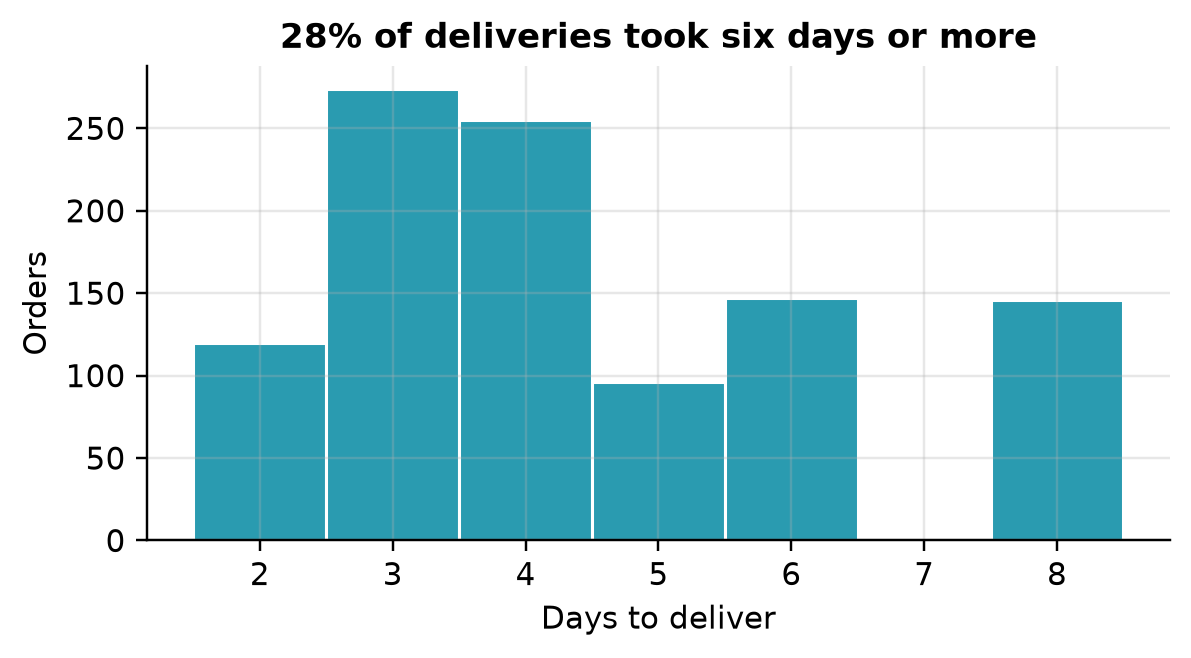

In [ ]:
days = orders["shipping_days"].dropna().astype(int)
slow = (days >= 6).mean()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(days, bins=np.arange(days.min(), days.max() + 2) - 0.5,
        color="#2a9bb0", edgecolor="white")
ax.set_xticks(range(days.min(), days.max() + 1))
ax.set_xlabel("Days to deliver")
ax.set_ylabel("Orders")
ax.set_title(f"{slow:.0%} of deliveries took six days or more")
plt.show()

*Delivery times of the coffee shop's orders, one bar per day.*

Bin edges at half-days, from `np.arange(...) - 0.5`, center each bar on a whole number of days, so a bar means exactly "2 days", "3 days" and so on. There are no 7-day deliveries in the data, which the gap shows. Of all deliveries, 28% took six days or more.

## Exercise 15.6

*Save the chart from exercise 15.3 as PNG at 300 dpi and as SVG and PDF, and compare the three file sizes.*

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for (name, group), marker in zip(penguins.groupby("species"), "os^"):
    ax.scatter(group["bill_length_mm"], group["bill_depth_mm"], s=14,
               marker=marker, label=name, alpha=0.7)
ax.legend()
for ext in ["png", "svg", "pdf"]:
    fig.savefig(f"bills.{ext}", dpi=300, bbox_inches="tight")
    print(f"bills.{ext}  {Path(f'bills.{ext}').stat().st_size:>9,} "
          "bytes")
plt.close(fig)

bills.png    142,637 bytes
bills.svg     71,751 bytes
bills.pdf     14,235 bytes


`dpi` matters only for the PNG; the vector formats store every point as a shape. With a few hundred points, all three files are small; with hundreds of thousands of points, a vector file grows with every point, and a PNG becomes the smaller choice.

## Exercise 15.7

*Write `bar_chart(series, title, color)` that draws a sorted horizontal bar chart with value labels and no x axis, and returns the figure. Use it for revenue by product and by state.*

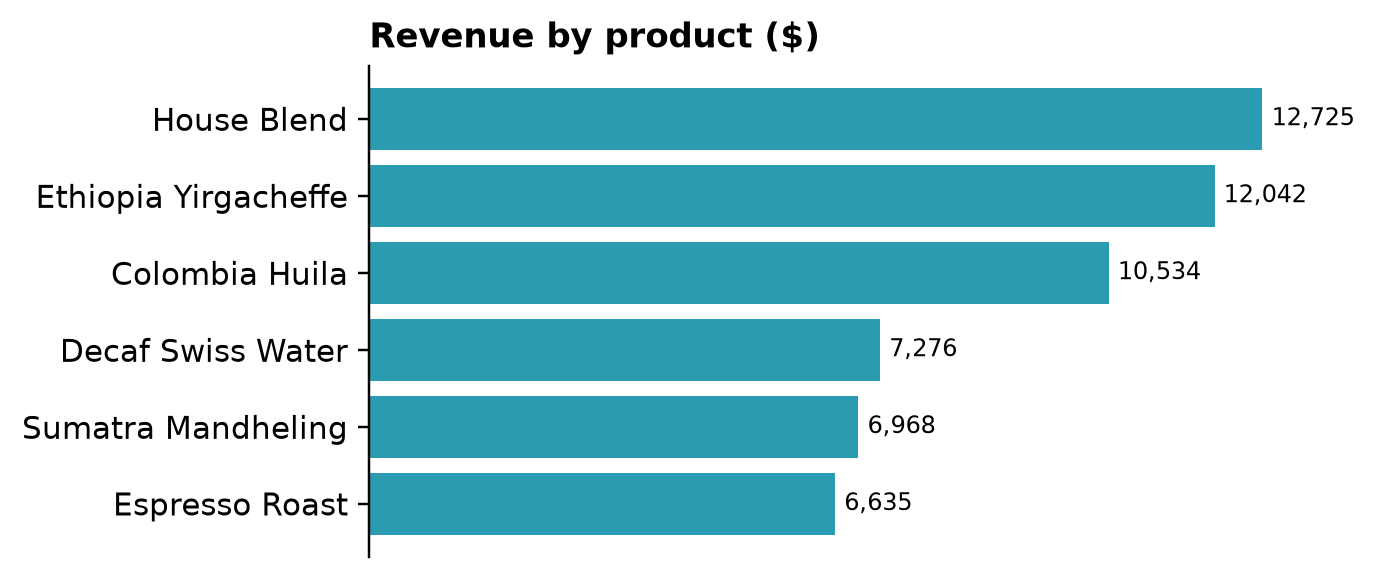

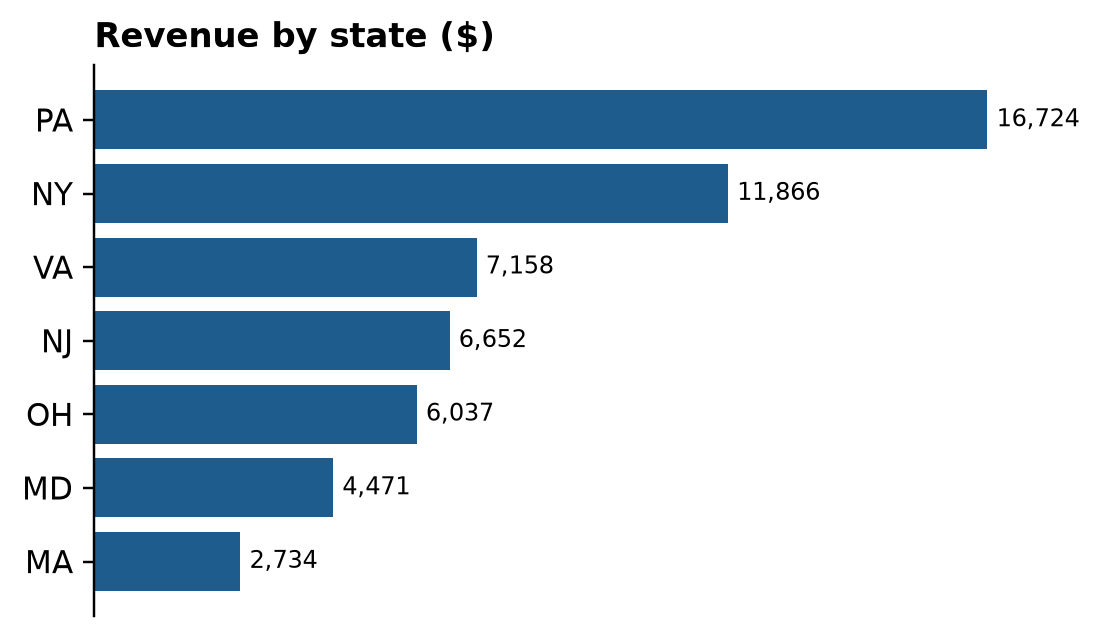

In [ ]:
def bar_chart(series, title, color="#2a9bb0", fmt="{:,.0f}"):
    data = series.sort_values()
    fig, ax = plt.subplots(figsize=(5.5, 0.35 * len(data) + 0.8))
    bars = ax.barh(data.index.astype(str), data.values, color=color)
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title, loc="left")
    return fig


revenue = orders["quantity"] * orders["unit_price"]
bar_chart(revenue.groupby(orders["product"]).sum(),
          "Revenue by product ($)")
bar_chart(revenue.groupby(orders["state"]).sum(), "Revenue by state ($)",
          color="#1d5c8c")
plt.show()

*Two charts drawn by the same function: revenue by product and by state.*

The figure's height grows with the number of bars, so a chart of seven states and one of six products both look right. Returning the figure lets the caller save it or change it further. Both calls draw their own figure, and `plt.show()` shows both. A small function like this is how teams keep their charts consistent.